# ADASYN: balancimi i klasës së pabalancuar

**Prokurimi publik në Shqipëri, 2016–2025** · Grupi 13 · Përgatitja dhe vizualizimi i të dhënave

**Detyra:** aplikimi i algoritmit **ADASYN** (*Adaptive Synthetic Sampling*) mbi dataset-in e projektit (277,764 tenderë), pas para-procesimit të Fazës I.

### Çka është ADASYN?
Kur një klasë është shumë më e vogël se tjetra, modeli mëson kryesisht klasën e madhe dhe e "injoron" të voglën. ADASYN e balancon duke **krijuar shembuj sintetikë** të klasës së vogël:

1. Sa shembuj duhen gjithsej: **G = (nr. i klasës së madhe − nr. i klasës së vogël) × β**, ku β = 1 do të thotë balancim i plotë.
2. Për çdo shembull të klasës së vogël gjen **k = 5 fqinjët më të afërt** dhe llogarit **rᵢ = Δᵢ / k**, ku Δᵢ = sa fqinjë i përkasin **klasës së madhe**.
3. Normalizon rᵢ (shuma = 1) dhe krijon **gᵢ = r̂ᵢ × G** shembuj rreth secilit shembull.
4. Çdo shembull sintetik krijohet **mes shembullit dhe një fqinji të klasës së vogël**: **s = xᵢ + λ · (x_zi − xᵢ)**, me λ ∈ [0, 1].

**Dallimi nga SMOTE:** SMOTE krijon **të njëjtin numër** shembujsh për çdo shembull të klasës së vogël. ADASYN krijon **më shumë aty ku klasa e vogël është më e vështirë** për t'u mësuar, pra te shembujt e rrethuar nga klasa e madhe.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
from imblearn.over_sampling import ADASYN
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from src.common.data_loading import read_years
from src.final.final_dataset import build
from src.balancing.adasyn import (TARGET, NUMERIC, BINARY, CATEGORICAL, select,
                                  fit_preprocess, apply_preprocess, class_table, evaluate)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 1. Të dhënat
Dataset-i final i Fazës I ndërtohet nga 10 CSV-të e APP-së (`data/raw/`) me të njëjtin kod si `prokurimi_final.csv`.

In [2]:
df, _ = build(read_years("data/raw"))
print(f"{len(df):,} tenderë x {df.shape[1]} kolona")

277,764 tenderë x 84 kolona


## 2. Klasa e pabalancuar: `single_bidder`
`single_bidder = 1` kur tenderi ka marrë **vetëm një ofertë**. Kjo është **konkurrencë e dobët**, një sinjal rreziku në prokurim. Vetia u krijua në Fazën I (pjesa *procedura dhe konkurrenca*).

In [3]:
counts = df[TARGET].value_counts().rename(index={False: "0: jo vetëm një ofertë (0 ose 2+)", True: "1: vetëm një ofertë"})
pd.DataFrame({"tenderë": counts, "%": (counts / counts.sum() * 100).round(2)})

,tenderë,%
single_bidder,,
0: jo vetëm një ofertë (0 ose 2+),240489,86.58
1: vetëm një ofertë,37275,13.42


Vetëm **13.42%** e tenderëve janë në klasën 1. Raporti është rreth **1 me 6.5**, pra klasa është e pabalancuar.

## 3. Vetitë
Përdoren vetëm vetitë që **dihen kur shpallet tenderi**. Asgjë nga ofertat, fituesi ose anulimi nuk përdoret, sepse do ta zbulonte përgjigjen (*data leakage*).

In [4]:
X, y = select(df)
print("Numerike:", NUMERIC)
print("Binare:", BINARY)
print("Kategorike (one-hot):", CATEGORICAL)
X.head()

Numerike: ['Fondi_limit_log', 'cpv_count', 'ditet_publikim_hapje', 'kohezgjatja_e_tenderit', 'muaji_publikimit', 'year']
Binare: ['Fondi_limit_missing', 'is_framework_agreement', 'periudhe_parazgjedhore', 'gjate_covid', 'publikim_ne_dhjetor']
Kategorike (one-hot): ['Lloji_i_procedures', 'Tipi_i_kontrates', 'primary_cpv_division']


,Fondi_limit_log,cpv_count,ditet_publikim_hapje,kohezgjatja_e_tenderit,muaji_publikimit,year,Fondi_limit_missing,is_framework_agreement,periudhe_parazgjedhore,gjate_covid,publikim_ne_dhjetor,Lloji_i_procedures,Tipi_i_kontrates,primary_cpv_division
0,12.429220,1,1,4,4,2024,0,False,0,0,0,Small Value,Supplies,16
1,11.373100,1,1,1,7,2021,0,False,0,1,0,Small Value,Supplies,66
2,13.592368,1,1,1,12,2018,0,False,0,0,1,Small Value,Supplies,18
3,12.939284,2,0,1,4,2024,0,False,0,0,0,Small Value,Supplies,37
4,12.542548,1,0,1,7,2021,0,False,0,1,0,Small Value,Supplies,72


## 4. Ndarja trajnim/test (80/20)
Ndarja bëhet **para** ADASYN-it dhe është e shtresëzuar (`stratify=y`). **ADASYN aplikohet vetëm mbi trajnimin**; testi ruan raportin real të klasave, që vlerësimi të jetë i ndershëm.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print(f"Trajnimi: {len(X_train):,} (klasa 1 = {y_train.mean():.2%})")
print(f"Testi:    {len(X_test):,} (klasa 1 = {y_test.mean():.2%})")

Trajnimi: 222,211 (klasa 1 = 13.42%)
Testi:    55,553 (klasa 1 = 13.42%)


## 5. Përgatitja për ADASYN
ADASYN punon me **distanca** (fqinjët më të afërt), prandaj të gjitha vetitë duhet të jenë numerike dhe në të njëjtën shkallë:
- fondi që mungon → **mediana e trajnimit** (ADASYN nuk pranon `NaN`); mungesa mbetet e shënuar te `Fondi_limit_missing`;
- kategoritë → **one-hot**, me kategorinë `[MISSING]`;
- të gjitha → **z-score** (`StandardScaler`).

Hapat mësohen **vetëm nga trajnimi** dhe zbatohen njësoj te testi.

In [6]:
prep = fit_preprocess(X_train)
X_train_s = apply_preprocess(X_train, prep, fit=True)
X_test_s = apply_preprocess(X_test, prep)
print("Kolona pas one-hot:", X_train_s.shape[1])

Kolona pas one-hot: 73


## 6. ADASYN

In [7]:
adasyn = ADASYN(n_neighbors=5, random_state=42)
X_res, y_res = adasyn.fit_resample(X_train_s, y_train)
y_res = pd.Series(y_res, name=TARGET)

print(f"Shembuj sintetikë të krijuar: {len(y_res) - len(y_train):,}")
class_table(y_train, y_res)

Shembuj sintetikë të krijuar: 163,272


,set,klasa_0_jo_single_bidder,klasa_1_single_bidder,pct_klasa_1,raporti_0_me_1
0,Trajnimi para ADASYN,192391,29820,13.42,6.45
1,Trajnimi pas ADASYN,192391,193092,50.09,1.00


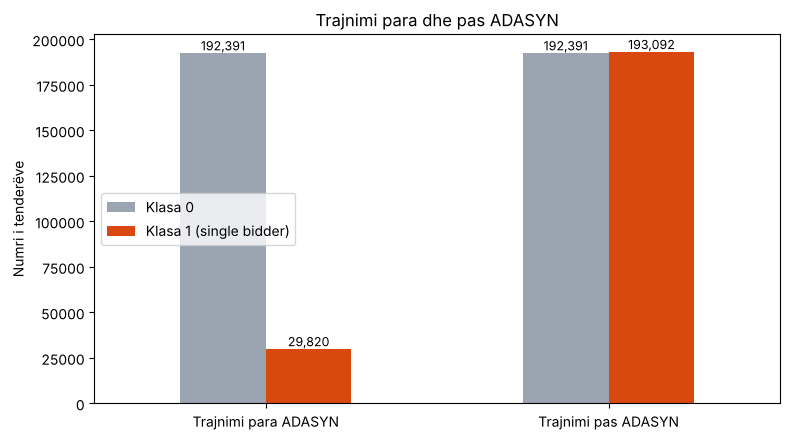

In [8]:
balance = class_table(y_train, y_res).set_index("set")[["klasa_0_jo_single_bidder", "klasa_1_single_bidder"]]
balance.columns = ["Klasa 0", "Klasa 1 (single bidder)"]
ax = balance.plot(kind="bar", figsize=(8, 4.5), rot=0, color=["#9aa5b1", "#d9480f"])
ax.set_title("Trajnimi para dhe pas ADASYN")
ax.set_ylabel("Numri i tenderëve")
ax.set_xlabel("")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

ADASYN e ngriti klasën 1 nga **29,820** në **193,092** (≈ 50%), duke krijuar **163,272** shembuj sintetikë. Numri nuk del saktësisht 50/50, sepse ADASYN rrumbullakon numrin e shembujve gᵢ për çdo shembull veç e veç.

## 7. A ndihmon ADASYN? I njëjti model pa dhe me ADASYN
Trajnohet **i njëjti model** (regresion logjistik) dy herë dhe vlerësohet mbi **të njëjtin test të paprekur**.
- **Recall (klasa 1):** nga tenderët me një ofertë, sa i kapi modeli.
- **Precision (klasa 1):** nga tenderët që modeli tha "një ofertë", sa ishin vërtet.
- **F1:** mesatarja harmonike e precision-it dhe recall-it.
- **Balanced accuracy:** mesatarja e recall-it të të dy klasave (nuk mashtrohet nga klasa e madhe).
- **ROC-AUC:** sa mirë i rendit modeli tenderët sipas rrezikut, pavarësisht pragut.

In [9]:
base = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
balanced = LogisticRegression(max_iter=1000).fit(X_res, y_res)

comparison = pd.DataFrame([
    evaluate("Pa ADASYN", base, X_test_s, y_test),
    evaluate("Me ADASYN", balanced, X_test_s, y_test),
]).set_index("modeli")
comparison

,precision_klasa_1,recall_klasa_1,f1_klasa_1,balanced_accuracy,roc_auc,TN,FP,FN,TP
modeli,,,,,,,,,
Pa ADASYN,0.5932,0.1946,0.2931,0.5870,0.8242,47103,995,6004,1451
Me ADASYN,0.3125,0.7504,0.4413,0.7473,0.8211,35792,12306,1861,5594


## 8. Interpretimi

| Metrika | Pa ADASYN | Me ADASYN | Çka do të thotë |
|---|---|---|---|
| **Recall (klasa 1)** | 0.19 | **0.75** | Modeli kap **75%** të tenderëve me një ofertë, kundrejt vetëm **19%** |
| **F1 (klasa 1)** | 0.29 | **0.44** | Balanc më i mirë mes precision-it dhe recall-it |
| **Balanced accuracy** | 0.59 | **0.75** | Modeli nuk e "injoron" më klasën e vogël |
| Precision (klasa 1) | **0.59** | 0.31 | Çmimi: më shumë alarme të rreme (FP 995 → 12,306) |
| ROC-AUC | 0.824 | 0.821 | Pothuajse i njëjtë |

**Përfundimi:**
- **Pa ADASYN**, modeli mësoi kryesisht klasën e madhe: nga **7,455** tenderë me një ofertë në test, kapi vetëm **1,451**.
- **Me ADASYN** kap **5,594**, pra 3.9 herë më shumë. Çmimi është më shumë alarme të rreme: precision bie nga 0.59 në 0.31.
- **ROC-AUC mbetet pothuajse i njëjtë.** ADASYN nuk i shtoi modelit informacion të ri; e **zhvendosi vendimin** drejt klasës së vogël, që të mos injorohet.
- Për një **auditues** që kërkon tenderë me rrezik, recall-i i lartë ka më shumë vlerë: më mirë të kontrollohen disa tenderë të tepërt sesa të humbasin 3/4 e tenderëve me një ofertë.

**Kujdes:**
- Shembujt sintetikë **nuk janë tenderë realë** dhe nuk shtohen në dataset-in `prokurimi_final.csv`. Përdoren **vetëm për trajnimin e modelit**.
- Vlerësimi bëhet **vetëm mbi tenderë realë** (testi).